# CA1 Data Preparation Ciaran Lynch

## Add python libraries to analysis

In [382]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np


### The assignment requires us to carried out analysis of a csv named student_dataV2
###  This csv was also attached with an excel file called student_data_Dictionary.
###  This excel file gave us a description of the variable names listed with a number value and  their associate meaning

In [383]:
# dict = pd.read_excel("student_data_dictionary.xlsx")

In [384]:
# dict

## Load the Dataset provided called student_dataV2

In [385]:
df = pd.read_csv("student_dataV2.csv")

# Characterisation of the data set

### Check  the data loaded correctly

In [386]:
df.head(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,...,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,...,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Exploratory Data Analysis

In [387]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   object 
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4424 non-null   object 
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [388]:
df.shape

(4424, 37)

#### We can see that the dataset contains 4424 rows of data and  37 columns
#### and we have a target categorical variable with a classification task
#### (dropout, enrolled, and graduate) at the end of the normal duration of the course

### Rename the columns to make it more readable

In [389]:
df = df.rename(columns={
    "Marital status": "maritial_status",
    "Application mode": "application_mode",
    "Application order": "application_order",
    "Course": "course",
    "Daytime/evening attendance": "course_time",
    "Previous qualification": "previous_qual",
    "Previous qualification (grade)": "previous_grade",
    "Nacionality": "nationality",
    "Mother's qualification": "mothers_qual",
    "Father's qualification": "fathers_qual",
    "Mother's occupation.": "mothers_occupation",
    "Father's occupation": "fathers_occupation",
    "Admission grade": "admission_grade",
    "Educational special needs": "special_needs",
    "Debtor": "debtor",
    "Tuition fees up to date": "tuition_paid",
    "Gender": "gender",
    "Age at enrollment": "enrollment_age",
    "International": "international",
    "Curricular units 1st sem (credited)": "1st_sem_credit",
    "Curricular units 1st sem (enrolled)": "1st_sem_enrolled",
    "Curricular units 1st sem (evaluations)": "1st_sem_evaluation",
    "Curricular units 1st sem (approved)": "1st_sem_approved",
    "Curricular units 1st sem (grade)": "1st_sem_grade",
    "Curricular units 1st sem (without evaluations)": "1st_sem_without_eval",
    "Curricular units 2nd sem (credited) ": "2nd_sem_credit",
    "Curricular units 2nd sem (enrolled) ": "2nd_sem_enrolled",
    "Curricular units 2nd sem (evaluations)": "2nd_sem_evaluation",
    "Curricular units 2nd sem (approved) ": "2nd_sem_approved",
    "Curricular units 2nd sem (grade)": "2nd_sem_grade",
    "Curricular units 2nd sem (without evaluations)": "1st_sem_without_eval",
    "Unemployment rate": "unemployed_rate",
    "Inflation rate": "inflation_rate"
    } 
    )

In [390]:
df.head(3)

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,...,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,...,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,...,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout


## Carry out analysis on variable columns
### 1.  Check the Target variable for issues, as this is the main variable for analysis

In [391]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled', 'Grad', 'graduate', 'Drop',
       'dropout'], dtype=object)

### See errors in categorising the variables, with incorrect wording, ie Grad instead of Graduate
### These need to be replaced

In [392]:
df["Target"] = df["Target"].replace(
    {
        "Grad": "Graduate",
        "graduate": "Graduate",
        "Drop" : "Dropout",
        "dropout": "Dropout"
    }
)

In [393]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

### Create a new interger field from the Target
###  for correlation puropse, based on Graduated = 1, else 0

In [394]:
df["Graduated"]= df["Target"].map(
    {"Dropout": 0,
     "Enrolled": 0,
     "Graduate":1}
)

In [395]:
df["Graduated"].unique()

array([0, 1])

In [396]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 38 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   maritial_status                      4424 non-null   object 
 1   application_mode                     4423 non-null   float64
 2   application_order                    4423 non-null   float64
 3   course                               4421 non-null   float64
 4   course_time                          4424 non-null   int64  
 5   previous_qual                        4424 non-null   int64  
 6   previous_grade                       4420 non-null   float64
 7   nationality                          4424 non-null   object 
 8   mothers_qual                         4424 non-null   int64  
 9   fathers_qual                         4423 non-null   float64
 10  Mother's occupation                  4423 non-null   float64
 11  fathers_occupation            

### 2. Check the information on maritial_status

In [397]:
df["maritial_status"].unique()

array(['1', '2', '4', '?', '3', '5', '6'], dtype=object)

### More errors found
### Replace the ? error with nan using numpy feature

In [398]:
df["maritial_status"] = df["maritial_status"].replace("?", np.nan)

## Replace the numeric values with the appropriate values per student_data_dictionary
### Note this is an object field

In [399]:
df["maritial_status"] = df["maritial_status"].replace(
    {
        "1": "single",
        "2": "married",
        "3" : "widower",
        "4": "divorced",
        "5" : "facto union",
        "6" : "legally seperated"
    }
)

In [400]:
df["maritial_status"].unique()

array(['single', 'married', 'divorced', nan, 'widower', 'facto union',
       'legally seperated'], dtype=object)

### 3. Carry out analysis of enrollment_age

In [401]:
df["enrollment_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', 'UnKnown', '30', '31', '32', '40', '42', '48',
       '49', '46', '41', '70', '60', '53', '51', '52', '54', '61', '58',
       '59', '17', '57', '62', nan], dtype=object)

####  More errors found in the rows
#### See the presence of unknown, nan variables in the rows
####  replace unknown to nan using numpy

In [402]:
df["enrollment_age"] = df["enrollment_age"].replace("UnKnown", np.nan)

In [403]:
df["enrollment_age"].unique()

array(['20', '19', '45', '50', '18', '22', '21', '34', '37', '43', '55',
       '39', '29', '24', '27', '23', '26', '33', '35', '25', '44', '36',
       '47', '28', '38', nan, '30', '31', '32', '40', '42', '48', '49',
       '46', '41', '70', '60', '53', '51', '52', '54', '61', '58', '59',
       '17', '57', '62'], dtype=object)

In [404]:
df["enrollment_age"].dtype


dtype('O')

### Here we can see that although it looks like a numeric field, it is actually an object
### Using pandas library, change type to int, use the errors=coerce to also change the nan rows as numeric

In [405]:
df["enrollment_age"] = pd.to_numeric(df["enrollment_age"], errors="coerce")

In [406]:
df["enrollment_age"].dtype

dtype('float64')

### There is quite a large spread of age values.
### For further analysis, it would be helpful to divide into age range bins, using the pandas cut method

In [407]:
df["age_range"] = pd.cut(
    df["enrollment_age"],
    bins = [0,19,23,30,40,50,100],
    labels=[
        "18-19",
        "20-23",
        "24-30",
        "31-40",
        "41-50",
        "Over50"
    ]
)

In [408]:
df["age_range"].value_counts()

age_range
18-19     1951
20-23     1202
24-30      607
31-40      437
41-50      182
Over50      43
Name: count, dtype: int64

### 4. Carry Out Analysis of Course Time
### Daytime or evening


In [409]:
df["course_time"].unique()

array([1, 0])

In [410]:
df["course_time"].value_counts()

course_time
1    3941
0     483
Name: count, dtype: int64

###  1 = daytime and 0 = evening
### From the above value counts, we see that the majority of the students are daytime attenders
###  Suggesting that the majority of the students are under 30 and attending a full time day course

### 5. Carry out analysis of tuition_paid

In [411]:
df["tuition_paid"].unique()

array(['1', '0', nan, '?'], dtype=object)

### More errors found - replace the ? with nan
### as per the excel dictionary
### Tuition paid = 1, else 0
### note this variable is an object so will need to be converted to numeric using pandas pd.to_numeric

In [412]:
df["tuition_paid"] = df["tuition_paid"].replace("?", np.nan)

In [413]:
# change to numeric before renaming the values
df["tuition_paid"] = pd.to_numeric(df["tuition_paid"], errors="coerce")

In [414]:
df["tuition_paid"].unique()

array([ 1.,  0., nan])

In [415]:
df[df["tuition_paid"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,Graduated,age_range
3838,single,1.0,1.0,9147.0,1,1,115.0,1,38,1.0,...,10,1,10.0,0,7.6,2.6,0.32,Dropout,0,20-23
4089,married,43.0,1.0,8014.0,0,14,133.1,1,34,34.0,...,15,1,13.0,1,9.4,-0.8,-3.12,Dropout,0,31-40


### only 2 errors in the tuition paid variable, which are now updated to appear as nan

### 6. Carry out analysis of international variable
###  Note this is variable is currently listed as a float
###  1= yes and 0= No

In [416]:
df["international"].unique()

array([ 0.,  1., nan])

In [417]:
df[df["international"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,Graduated,age_range
352,single,1.0,4.0,171.0,1,1,127.0,1,1,1.0,...,0,0,0.0,0,9.4,-0.8,-3.12,Dropout,0,18-19


### 1 record shows a missing value, listed  as nan

### 7. Carry out analysis of gender variable
### Currently listed as an int with 1's and 0's
### 1 = male and 0 = female

In [418]:
df["gender"].unique()

array([1, 0])

### No errors in the rows found


### 8. Carry out analysis by admission_grade, 
### currently correctly listed as a float

In [419]:
df["admission_grade"].unique()

array([127.3, 142.5, 124.8, 119.6, 141.5, 114.8, 128.4, 113.1, 129.3,
       123. , 130.6, 119.3, 130.2, 111.8, 137.1, 120.7, 137.4, 136.3,
       124.6, 120.3, 121.8, 125.5, 114.9, 123.9, 157. , 116.4, 131. ,
       122.1, 118.8, 150. , 130. , 138.8, 134.5, 131.4, 102.5, 128.8,
       122.9, 113.9, 120. , 121.1, 120.4, 100.6, 121.4, 109.7, 134.1,
       127.6, 132.4, 133.4, 126.1, 113.5, 121.3, 159.3, 129.1, 155.3,
       139.8, 115.2, 131.9, 126. , 120.9, 128.2, 120.1, 100. , 134. ,
       130.8, 135.8, 111.7, 132.9, 115.5, 106. , 117. , 110.2, 155.7,
       180.4, 110. , 161. , 117.6, 128.7, 112.2, 100.8, 105. , 114. ,
       137. , 124.9, 134.3, 111.5, 160. , 117.4, 122.2, 118.2, 106.7,
       108.2, 107. , 136.1, 115.3, 140.4, 113.4, 118.6, 122.3, 127.9,
       117.1, 145.3, 122.6, 128. , 123.7, 131.7, 133.2, 109.3, 113. ,
       157.9, 112.1, 174.7, 110.1,  99.7, 121. , 119.1, 124.7, 117.2,
       131.5, 121.7, 123.4, 132.8, 108.7, 138.1, 126.5, 127.4, 123.6,
       122. , 125.8,

In [420]:
df["admission_grade"].mean()

np.float64(126.98851198552693)

In [421]:
df["admission_grade"].min()

95.0

In [422]:
df["admission_grade"].max()

190.0

### No errors found in the rows for the admission_grade variable
###  This allowed me to carry out a few math functions
###  admission grades run from 95-190, with an average of 126.98

### 9. Carry out analysis of 1st and 2nd semester evaluations

In [423]:
df["1st_sem_evaluation"].unique()

array([ 0,  6,  8,  9, 10,  5,  7, 14, 12, 15, 13, 11,  1, 17, 18, 19, 21,
        4, 16,  3, 24,  2, 22, 45, 20, 26, 29, 36, 32, 23, 27, 31, 28, 25,
       33])

In [424]:
df["1st_sem_evaluation"].min()

0

In [425]:
df["1st_sem_evaluation"].max()

45

In [426]:
df["2nd_sem_evaluation"].unique()

array([ 0,  6, 10, 17,  8,  5,  7, 14,  9, 12, 11, 13, 19,  3, 15, 16,  4,
       18,  2, 21,  1, 26, 27, 22, 20, 24, 28, 23, 25, 33])

In [427]:
df["2nd_sem_evaluation"].min()

0

In [428]:
df["2nd_sem_evaluation"].max()

33

### No errors found with the evaluations fields
###  listed as integer fields, so i could carry out a few math functions

### 10. Carry out analysis of the 1st semester grade & 2nd semester grade

In [429]:
# df["1st_sem_grade"].unique()

In [430]:
df[df["1st_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,Graduated,age_range
4417,single,1.0,1.0,9070.0,1,1,132.0,1,1,1.0,...,6,6,13.5,0,16.2,0.3,-0.92,Graduate,1,20-23


In [431]:
df["1st_sem_grade"].max()

18.875

In [432]:
# df["2nd_sem_grade"].unique()

In [433]:
df[df["2nd_sem_grade"].isna()]

,maritial_status,application_mode,application_order,course,course_time,previous_qual,previous_grade,nationality,mothers_qual,fathers_qual,...,2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Target,Graduated,age_range
3696,single,43.0,1.0,9254.0,1,1,112.0,1,37,37.0,...,7,5,NaN,0,9.4,-0.8,-3.12,Graduate,1,20-23


In [434]:
df["2nd_sem_grade"].max()

18.571428571428573

### From analysis, both variables have 1 nan field
### They are listed as floats which allowed me to carry out a math function

In [435]:
df["previous_qual"].unique()

array([ 1, 19, 42, 39, 10,  3, 40,  2,  4, 12, 43, 15,  6,  9, 38,  5, 14])

## Dealing with nan values

In [436]:
total_rows = len(df)
print("Total rows of data before dealing with missing rows: ", total_rows)

Total rows of data before dealing with missing rows:  4424


In [437]:
df = df.dropna()

In [438]:
new_rows = len(df)

In [439]:
print("rows of data after dropping missing values: " , new_rows)

rows of data after dropping missing values:  4402


In [440]:
total_dropped = total_rows -  new_rows
total_dropped

22

In [441]:
total_dropped / total_rows *100

0.4972875226039783

In [442]:
df.isnull().sum()

maritial_status                        0
application_mode                       0
application_order                      0
course                                 0
course_time                            0
previous_qual                          0
previous_grade                         0
nationality                            0
mothers_qual                           0
fathers_qual                           0
Mother's occupation                    0
fathers_occupation                     0
admission_grade                        0
Displaced                              0
special_needs                          0
debtor                                 0
tuition_paid                           0
gender                                 0
Scholarship holder                     0
enrollment_age                         0
international                          0
1st_sem_credit                         0
1st_sem_enrolled                       0
1st_sem_evaluation                     0
1st_sem_approved

## Missing rows analysis
#### in total only 22 rows had missing data, this represented 0.49% of the overall dataset
### dropping the missing data, will have a negligible impact on the overall sample size

## Discriptive Statistics

In [443]:
df.describe()

,application_mode,application_order,course,course_time,previous_qual,previous_grade,mothers_qual,fathers_qual,Mother's occupation,admission_grade,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),2nd_sem_evaluation,Curricular units 2nd sem (approved),2nd_sem_grade,1st_sem_without_eval,unemployed_rate,inflation_rate,GDP,Graduated
count,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,...,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000,4402.000000
mean,18.674012,1.728760,8858.693321,0.890731,4.575193,132.631463,19.582690,22.275784,10.987279,126.996093,...,0.542708,6.235120,8.065198,4.437528,10.228262,0.150613,11.569673,1.230395,0.005768,0.499318
std,17.464563,1.314639,2060.038543,0.312011,10.211305,13.198898,15.599265,15.340217,26.480602,14.478014,...,1.921693,2.195907,3.949243,3.016252,5.214313,0.755371,2.664913,1.381645,2.266889,0.500056
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000,0.000000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,...,0.000000,5.000000,6.000000,2.000000,10.800000,0.000000,9.400000,0.300000,-1.700000,0.000000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,...,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000,0.000000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,...,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000,1.000000
max,53.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,...,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000,1.000000


#### Check the target column for value counts

In [444]:
df["Target"].value_counts()

Target
Graduate    2198
Dropout     1416
Enrolled     788
Name: count, dtype: int64

### Show Student outcomes on a chart

Text(0.5, 1.0, 'Student Outcomes')

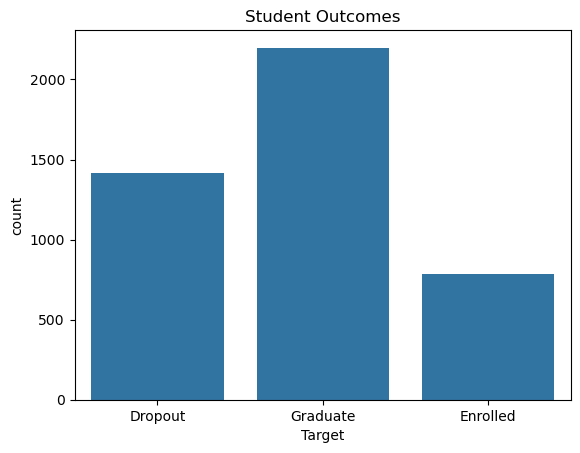

In [445]:
sns.countplot(
    data=df,
    x="Target")

plt.title("Student Outcomes")

### The above Target outcome shows a balanced result, with 2,198 Graduates and 1,416 Dropouts, we also had 788 enrolled
### Graduates were the largest category, showing that course completions were the most common
### Although a large dropout rate may require further analysis

Text(0.5, 1.0, 'Student maritial status')

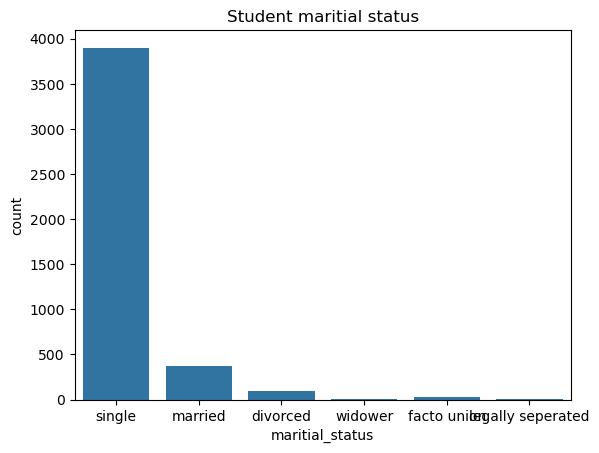

In [446]:
sns.countplot(
    data=df,
    x="maritial_status")

plt.title("Student maritial status")

Text(0.5, 1.0, 'Students by age range')

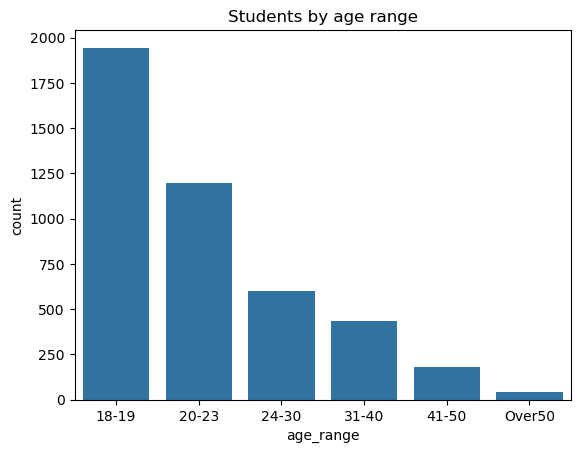

In [447]:
sns.countplot(
    data=df,
    x="age_range")

plt.title("Students by age range")

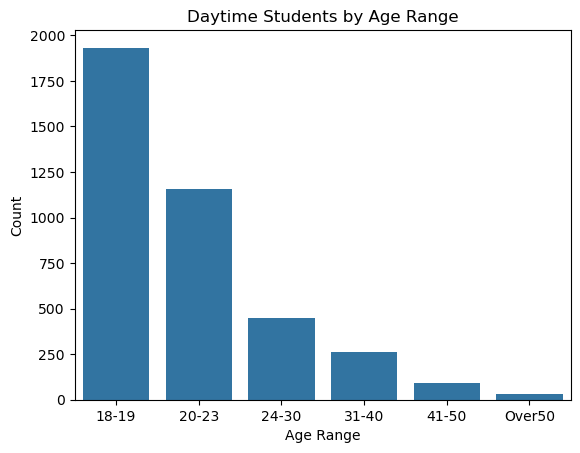

In [448]:
sns.countplot(
    data=df[df["course_time"] ==  1],
    x="age_range"
)

plt.title("Daytime Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

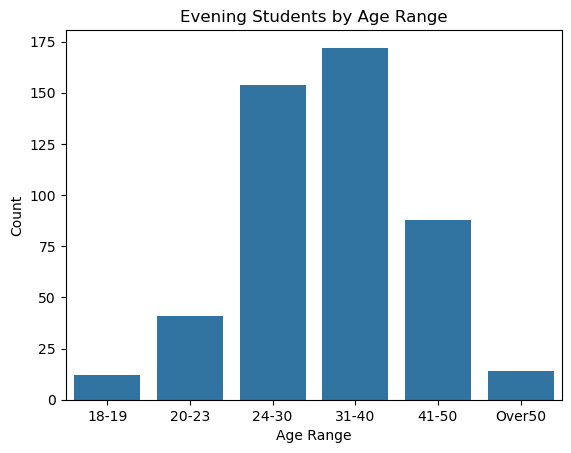

In [449]:
sns.countplot(
    data=df[df["course_time"] ==  0],
    x="age_range"
)

plt.title("Evening Students by Age Range")
plt.xlabel("Age Range")
plt.ylabel("Count")
plt.show()

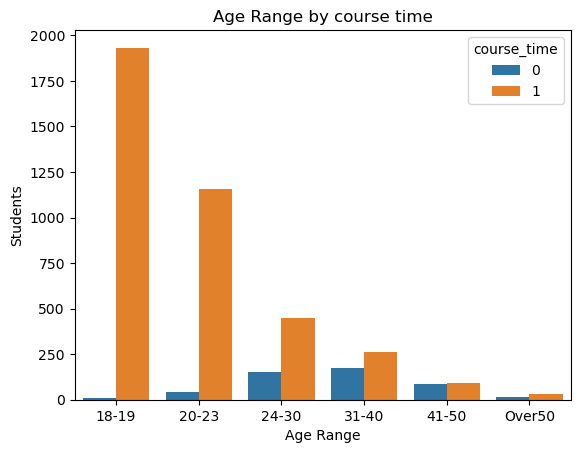

In [450]:
sns.countplot(
    data=df,
    x="age_range",
    hue="course_time"
)

plt.title("Age Range by course time")
plt.xlabel("Age Range")
plt.ylabel("Students")
plt.show()

In [451]:
## Chart analysis
###  We can see from the above charts that younger students dominate the daytime courses, particularly in the 18-19 and 20-23 age ranges
### Attendance of evening courses have more of an uptake with the older students
### This is to be expected given evening classes would generally be more part time for working adults

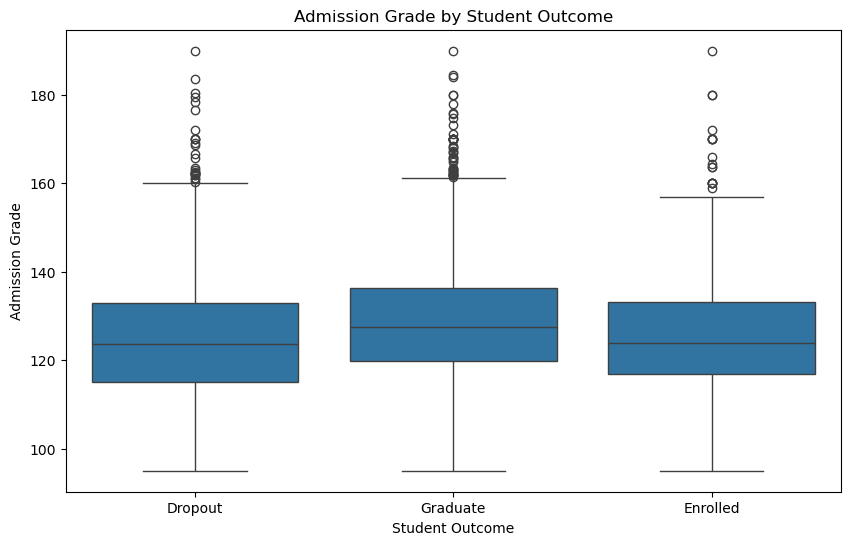

In [452]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["admission_grade"]
)
   

plt.title("Admission Grade by Student Outcome" )
plt.xlabel("Student Outcome")
plt.ylabel("Admission Grade")

plt.show()

### Admission Grade Boxplot Analysis
### The above boxplot would suggest that students with higher admission grades tended to have higher graduation rates
### However the overlap detween groups indicates that admission grades alone does not fully explain outcomes

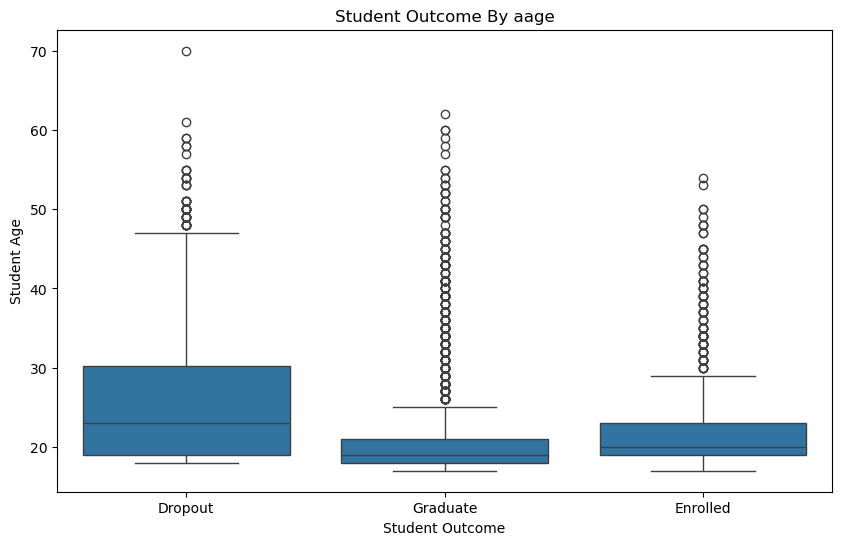

In [453]:
plt.figure(figsize=(10,6) )

sns.boxplot(
    data = df,
    x= df["Target"],
    y= df["enrollment_age"]
)
   

plt.title("Student Outcome By aage" )
plt.xlabel("Student Outcome")
plt.ylabel("Student Age")

plt.show()

## Enrollment Age Boxplot Analysis
### The above boxplot suggests Graduates tend to be slightly younger than those who dropped out
### Older students have a large variation in outcomes, this may be due to other committments outside of education

<Axes: xlabel='enrollment_age', ylabel='admission_grade'>

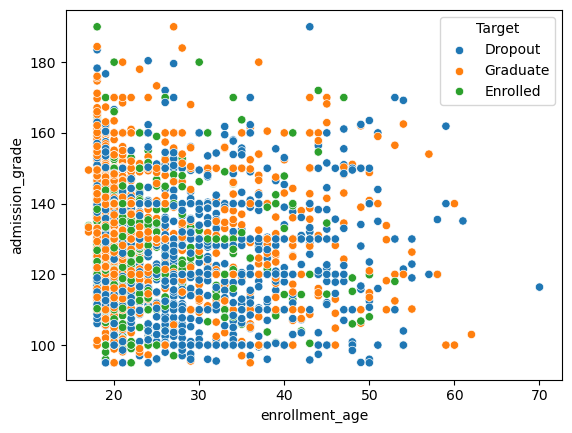

In [454]:
sns.scatterplot(
    data = df,
    x= "enrollment_age",
    y = "admission_grade",
    hue = "Target"
)

## Scatterplot Analysis
### There does not appear to be a strong linear relationship to enrollment age and admission grade
### However there is a larger concentration of graduates appring withh higher admission grades
### Suggesting higher admission grades leads to a higher chance of graduating

## Correlation

In [455]:
df_new = df[
    ["course",
     "enrollment_age", 
     "1st_sem_evaluation", 
     "2nd_sem_evaluation", 
     "1st_sem_grade",
     "2nd_sem_grade",
     "application_mode",
     "Graduated",
     "gender",
     "international",
     "tuition_paid",
     "course_time"
     
    ] 
    ].copy()

In [456]:
corr_matrix = df_new.corr(numeric_only=True)
corr_matrix

,course,enrollment_age,1st_sem_evaluation,2nd_sem_evaluation,1st_sem_grade,2nd_sem_grade,application_mode,Graduated,gender,international,tuition_paid,course_time
course,1.000000,0.042389,0.270618,0.276718,0.387269,0.346813,0.064023,0.029274,-0.099504,-0.027935,0.015622,-0.042973
enrollment_age,0.042389,1.000000,0.139080,0.054939,-0.157066,-0.173864,0.515411,-0.194836,0.150093,-0.009890,-0.177854,-0.461277
1st_sem_evaluation,0.270618,0.139080,1.000000,0.778619,0.417239,0.354151,0.225430,-0.004843,-0.021125,0.011529,0.027334,-0.044443
2nd_sem_evaluation,0.276718,0.054939,0.778619,1.000000,0.486871,0.452867,0.166468,0.021366,-0.041437,-0.005593,0.063724,0.016663
1st_sem_grade,0.387269,-0.157066,0.417239,0.486871,1.000000,0.836665,-0.119018,0.414136,-0.190203,0.005546,0.250003,0.064799
2nd_sem_grade,0.346813,-0.173864,0.354151,0.452867,0.836665,1.000000,-0.116440,0.474401,-0.199705,0.001145,0.296468,0.051140
application_mode,0.064023,0.515411,0.225430,0.166468,-0.119018,-0.116440,1.000000,-0.208025,0.161414,0.000212,-0.136659,-0.303140
Graduated,0.029274,-0.194836,-0.004843,0.021366,0.414136,0.474401,-0.208025,1.000000,-0.217846,-0.004168,0.327262,0.058504
gender,-0.099504,0.150093,-0.021125,-0.041437,-0.190203,-0.199705,0.161414,-0.217846,1.000000,-0.025505,-0.105646,-0.013500
international,-0.027935,-0.009890,0.011529,-0.005593,0.005546,0.001145,0.000212,-0.004168,-0.025505,1.000000,-0.044958,0.032380


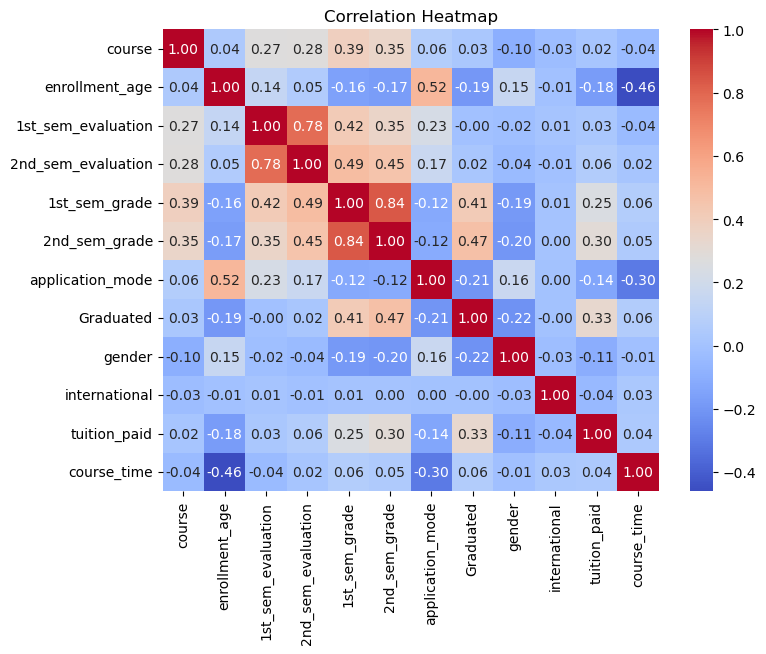

In [457]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    corr_matrix,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Heatmap")

plt.show()

### Correlation  analysis

### Measuring Graduated variable with all others:
### There is a noticeable positive correlation between Graduated to 1st semester grade and 2nd semester grade
### Indicating academic performance results in sucessful completion
### Also tuition paid has a 0.33 positive correlation to graduation 
### indicating that fullly paying for a course may be a positive driving factor in completion
### Notice also the strong positive correlation in 1st and 2nd semester grades along with evaluation

## PCA